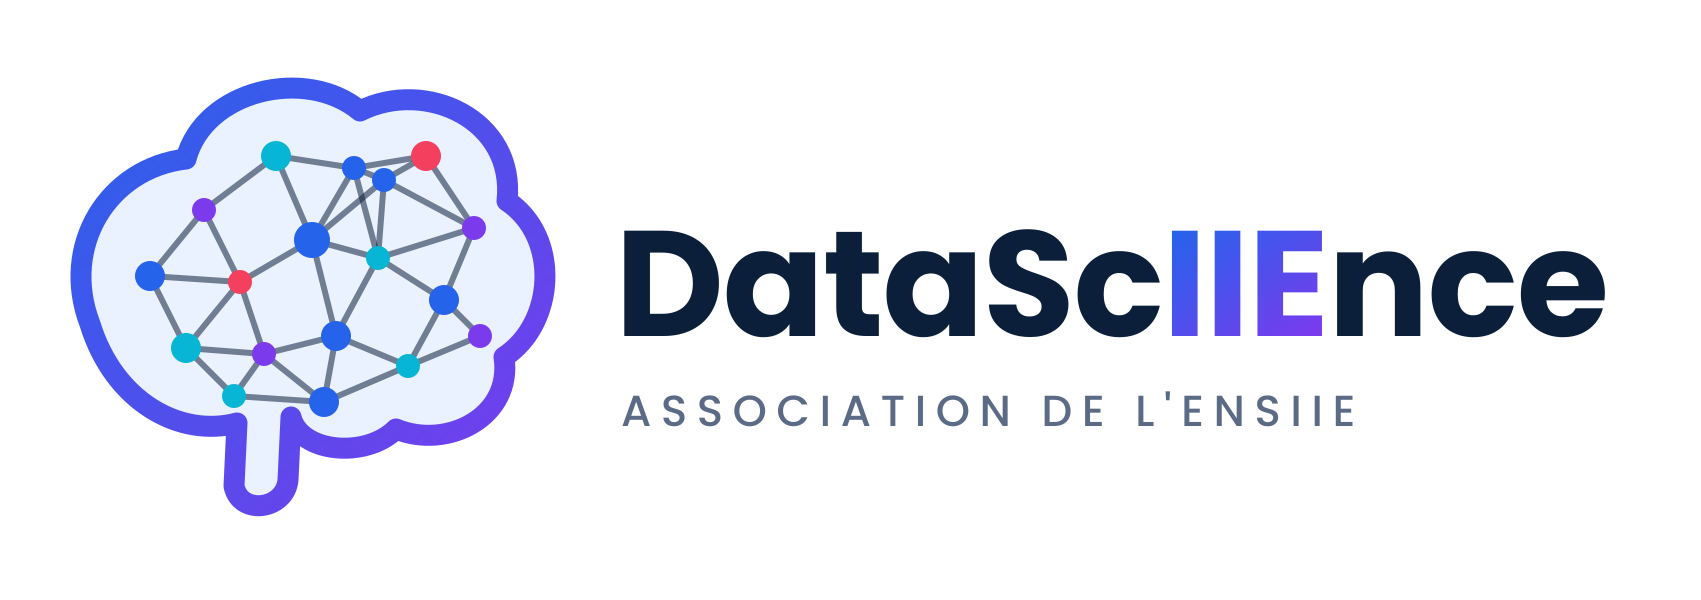

# Introduction au Deep Learning

## Qu'est ce que le Deep Learning

Le deep learning est une sous-catégorie du machine learning qui utilise des réseaux neuronaux multicouches, appelés réseaux neuronaux profonds, pour simuler le pouvoir de décision complexe du cerveau humain. Une forme ou une autre de deep learning alimente aujourd’hui la plupart des applications d’intelligence artificielle (IA) que nous utilisons.
La différence avec le Machine Learning (ML) réside dans le fait que le ML a souvent besoin d'un humain pour lui dire quoi regarder (par exemple : "fais attention à la couleur des pixels pour reconnaître une pomme"). Le Deep Learning est autonome. Vous lui donnez l'image brute, et il déterminera tout seul que la couleur est importante. Il apprend "par l'exemple", exactement comme un être humain.

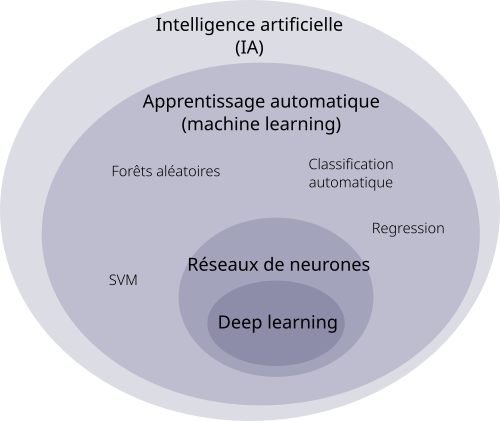

## Réseaux de Neurones (Neural Networks)

Le Deep Learning, c'est fondamentalement du biomimétisme. Dans notre cerveau, on a des neurones qui s'envoient des signaux électriques. Un réseau de neurones artificiel, c'est une imitation mathématique de ce processus.
On ne donne pas à l'ordinateur des règles fixes, On lui donne plutôt une structure capable d'apprendre par l'expérience.

Un réseau de neurones ("Deep Learning" quand il est profond) est structuré comme un mille-feuille en 3 parties, par exemple pour la reconnaissance d'un chiffre sur une image :

- La Couche d'Entrée (Input Layer) : Elle reçoit les données brutes. Dans notre cas, chaque neurone reçoit la valeur d'un pixel (0 à 255).

- Les Couches Cachées (Hidden Layers) : C'est la "boîte noire" où se fait le calcul. Les neurones s'y connectent entre eux pour extraire des caractéristiques de plus en plus complexes (lignes, courbes, formes).

- La Couche de Sortie (Output Layer) : Elle donne le résultat final (la prédiction). Ici, ce sera une probabilité pour chaque chiffre de 0 à 9.

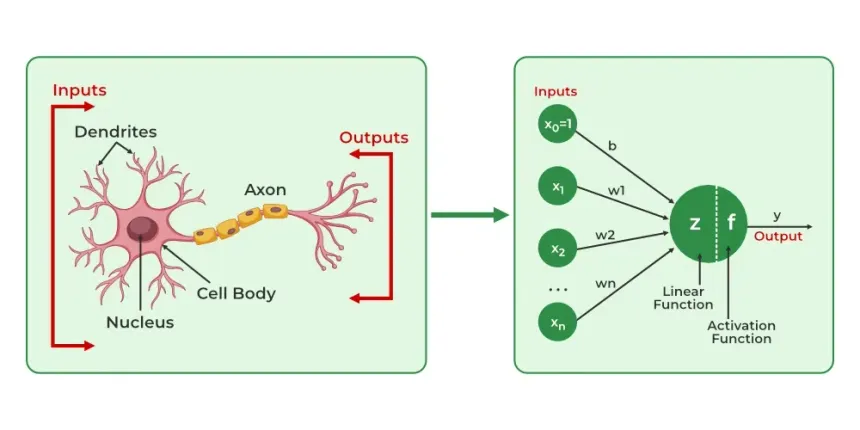

Chaque neurone artificiel fonctionne comme un petit décideur. Voici la formule mathématique qu'il applique :$$Output = f(\sum (Input \times Poids) + Biais)$$
- Les Entrées ($Input$) : Les données qui arrivent (ex: pixel allumé ou éteint).
- Les Poids ($Weights$) : C'est l'importance accordée à chaque entrée. Si un pixel est crucial pour définir un "8", son poids sera élevé. Le réseau apprend ces poids tout seul.
- Le Biais ($Bias$) : Un seuil d'activation. C'est une valeur qui permet au neurone de décaler sa réponse.
- La Fonction d'Activation ($f$) : Elle décide si le neurone doit "tirer" ou non (ex: ReLU, qui met les valeurs négatives à zéro, ou Softmax qui transforme les résultats en pourcentages).


1. Le "Forward Pass" (L'Essai)
Le réseau reçoit une image (par exemple un chiffre 7). L'information traverse toutes les couches, subit des multiplications par les Poids ($Weights$) actuels, et le réseau sort une prédiction.

2. La "Loss Function" (Le Calcul de l'Erreur)
C'est le juge impartial. On compare la prédiction du modèle avec la réalité (l'étiquette "7"). La fonction calcule une distance mathématique entre la réponse donnée et la bonne réponse.

3. Le "Gradient Descent" (La Stratégie de Correction)
C'est ici que la magie mathématique opère. Le but du jeu est de faire descendre la Loss vers 0.

4. La "Backpropagation" (La Mise à Jour)
Une fois que l'algorithme connaît la direction pour descendre (réduire l'erreur), il remonte le réseau en arrière (de la fin vers le début). Il va modifier légèrement chaque Poids de chaque neurone.
![Dense vs CNN](https://miro.medium.com/max/1400/1*3fA77_mLNiJTSgZFhYnU0Q.png)

# 0 - Présentation de quelques types de Réseaux de neurones (Neural Networks)

## 1 - Recurrent Neural Networks (RNN)

C'est l'architecture conçue pour les données séquentielles (le texte, le son, la bourse, la météo). Ici, l'ordre des données compte. Le problème avec les réseaux classiques, c'est qu'ils sont "amnésiques". Ils traitent chaque donnée isolément. Le RNN possède une boucle de rétroaction (Feedback Loop). C'est une forme de mémoire. Au lieu de juste aller de l'entrée vers la sortie, le neurone prend deux choses en entrée :

1. La nouvelle donnée (le mot actuel).

2. L'information de l'étape précédente (le contexte du mot d'avant).

Nous verrons cela plus en détail dans la séance NLP (Natural Language Processing).

## 2 - Convolutional Neural Networks (CNN)

C'est l'architecture reine pour la Vision par Ordinateur (reconnaissance faciale, voitures autonomes, analyse médicale). Le motif de connexion entre les neurones est inspiré par le cortex visuel des animaux.Ils consistent en un empilage de plusieurs couches, dont le but est de prétraiter de petites quantités d'informations. Les couches de convolution applique un kernel sur un input pour le modifier.
Le Problème des réseaux classiques, c'est qu'ils doivent "aplatir" l'image. Il transforme l'image en ligne de pixel alors qu'une image est une matrice. On perd de l'information.


1. Convolution (Le Scan) : Un petit filtre (Kernel) parcourt toute l'image. Il détecte des motifs locaux : d'abord des lignes, puis des courbes, puis des yeux... peu importe où ils sont dans l'image.

2. Pooling (Le Résumé) : On réduit la taille de l'image pour ne garder que l'information essentielle (ex: "il y a une forme ronde ici"). Cela allège le calcul.

3. Classification : À la fin, on connecte tout à un réseau classique.

Nous verrons cela plus en détail dans la séance CV (Computer Vision).

## Importation des bibliothèques importantes

Nous allons utiliser :
* **TensorFlow/Keras** : pour créer et entraîner notre réseau de neurones
* **NumPy** : pour manipuler les tableaux de données
* **Matplotlib/Seaborn** : pour visualiser l'apprentissage/évolution de l'erreur.
* **Pandas** : Pour la gestion des DataFrames.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras # création et l'entraînement de modèles d'apprentissage profond (Deep Learning).
from tensorflow.keras import layers # Utilisation des couches présent dans tensorflow.keras

# 1️ - Un seul neurone

Un réseau de neurones est composé de **neurones**, dont chacun ne réalise qu'un calcul très simple. Le neurone le plus simple est l'**unité linéaire** :

$$ y = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b $$

- `x` : les entrées (features)
- `w` : les **poids** (weights), un par entrée
- `b` : le **biais** (bias), qui décale la sortie indépendamment des entrées
- `y` : la sortie

Entraîner un neurone, c'est trouver les `w` et `b` qui rendent les prédictions les plus proches des cibles. Avec un seul neurone, on retrouve… une **régression linéaire**.

Dans Keras, on crée cette unité avec `layers.Dense(units=1, input_shape=[n])`.

In [ ]:
X = np.random.normal(0, 1, (1000, 3)) # moyenne, écart_type, taille
y = X @ np.array([3.0, -2.0, 0.5]) + 4 + np.random.normal(0, 0.2, (1000))
# y vecteur colonne combinaison linéaire des coeffs de X (ligne par ligne)
# auquel on y ajoute une constante et un léger bruit gaussien

# Un réseau avec 1 unité linéaire et 3 entrées
model = keras.Sequential([
    layers.Dense(units=1, input_shape=[3])
])

# même chose:
model = keras.Sequential([
    layers.Input(shape=[3]),
    layers.Dense(units=1)
    # units pour le nombre de sorties (1 pour le résultat final)
])

w, b = model.weights
print("Poids initiaux (aléatoires) :", w.numpy().flatten(), "| biais :", b.numpy())

model.compile(optimizer="adam", loss="mae")

model.fit(X, y,
          epochs=200,
          batch_size=32,
          verbose=0)

w, b = model.weights
print("Poids appris :", w.numpy().flatten().round(2), "| biais :", b.numpy().round(2))
print("Vérité        : [ 3. -2.  0.5] | biais : 4")

# 2 - Réseaux profonds (Deep Neural Networks)

Empiler des couches linéaires ne donne **qu'une autre fonction linéaire** : il faut de la **non-linéarité**. On l'obtient avec une **fonction d'activation** appliquée à la sortie de chaque couche.

La plus courante est **ReLU** : `max(0, x)`. Un neurone `Dense + ReLU` est un *rectified linear unit*.

Rappel sur le vocabulaire :
- **Couche d'entrée** : les données brutes.
- **Couches cachées** (*hidden layers*) : calculent des features de plus en plus abstraites. « Deep » = beaucoup de couches cachées.
- **Couche de sortie** : linéaire pour la régression (aucune activation).

In [ ]:
X = np.random.normal(0, 1, (500, 3))

y = (3.0 * X[:, 0]**2) - (2.0 * np.sin(X[:, 1])) + (0.5 * X[:, 0] * X[:, 2]) + 4
# y = 3*(x1)^2 - 2*sin(x2) + 0.5(x1*x3) + 4
y += np.random.normal(0, 0.2, (500))  # Ajout du bruit gaussien

# 2. Architecture du réseau multicouche
model = keras.Sequential([
    layers.Dense(units=16, activation="relu", input_shape=[3]),
    layers.Dense(units=8, activation="relu"),
    layers.Dense(units=1)
])

model.compile(optimizer="adam", loss="mae")

model.fit(X, y, epochs=200, batch_size=32, verbose=0)

# Évaluation des prédictions
X_test = np.array([[1.0, 0.5, -1.0]])
y_vrai = (3.0 * 1.0**2) - (2.0 * np.sin(0.5)) + (0.5 * 1.0 * -1.0) + 4
y_pred = model.predict(X_test, verbose=0)

print(f"Valeur réelle attendue : {y_vrai:.2f}")
print(f"Prédiction du modèle   : {y_pred[0][0]:.2f}")


In [ ]:
model.summary()

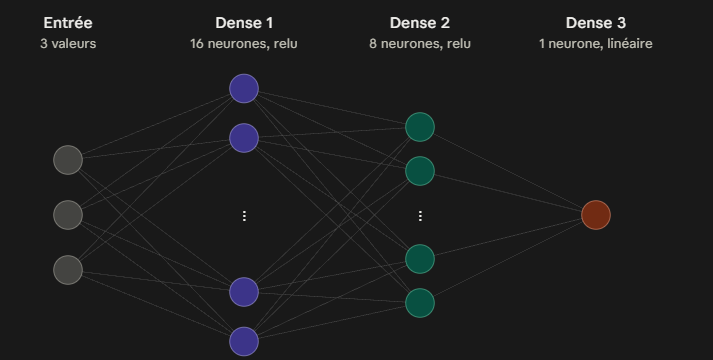


## Les fonctions d'activation
Il y en a de plusieurs sortes. Elles permettent d'exprimer/traduire des relations non_linéaires entre les couches.
Ci-dessous une liste non exhaustive de quelques fonctions d'activation représentée graphiquement.

In [ ]:
# Visualisation des activations courantes
x = np.linspace(-4, 4, 200)
fig, ax = plt.subplots()
ax.plot(x, np.maximum(0, x), label="ReLU")
ax.plot(x, np.where(x > 0, x, np.exp(x) - 1), label="ELU")
ax.plot(x, x / (1 + np.exp(-x)), label="Swish/SiLU")
ax.plot(x, 1 / (1 + np.exp(-x)), "--", label="Sigmoïde ")
ax.set_ylim(-2, 4)
ax.legend()
ax.set_title("Fonctions d'activation")
ax.grid()
plt.show()

# 3 - Stochastic Gradient Descent — comment un réseau apprend (phase d'optimisation)

Pour entraîner un réseau, il faut deux ingrédients :

- Une **fonction de perte** (*loss*) : mesure l'écart entre prédictions et cibles. En régression : **MAE** (erreur absolue moyenne), **MSE** ou **Huber**.

- Un **optimiseur** : l'algorithme qui ajuste les poids pour réduire la perte. **SGD** est le classique ; **Adam** est un excellent choix par défaut, qui adapte lui-même le pas.

**La descente de gradient** : on calcule le gradient de la perte par rapport aux poids, puis on fait un petit pas dans la direction opposée. À chaque itération :

1. On tire un **mini-batch** de données.
2. On prédit, on calcule la perte.
3. On met à jour les poids : `w ← w − η · ∇L`.

*Stochastique* = les batchs (lots) sont des échantillons aléatoires de taille `batch_size`

Un passage complet sur les données = une **epoch**.

Le **learning rate** `η` contrôle la taille des pas
- trop petit → apprentissage lent
- trop grand → instabilité

**Remarque** : Adam adapte le learning rate au fur et à mesure

## Petit exercice!
Faire correspondre `model_test` à l'image ci-dessous, mais avec un `layers.Dense` supplémentaire pour n'obtenir qu'une seule sortie!
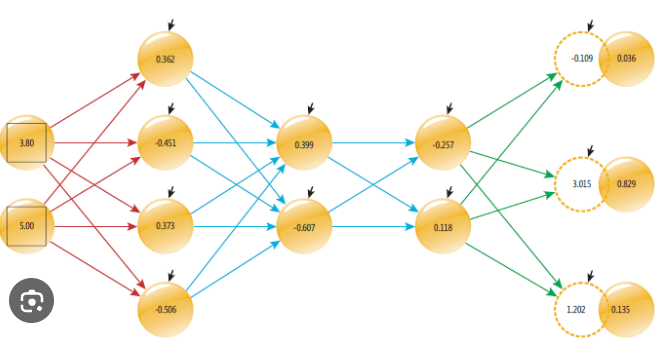

Combien de paramètres sont présents dans ce modèle?

In [ ]:
model_test = keras.Sequential([
    #TODO
  ])

# 4 - Evaluer le réseau de neurones
## Influence des epochs

In [ ]:
from sklearn.model_selection import train_test_split

def make_model():
    model = keras.Sequential([
        layers.Input(shape=(2,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1)  # Sortie linéaire pour la régression
    ])
    return model

X = np.random.normal(0, 1, (500, 2))
y = (3.0 * X[:, 0]**2) - (2.0 * np.sin(X[:, 1])) + (0.5 * X[:, 0] * X[:, 1]) + 4
# y = 3*(x1)^2 - 2*sin(x2) + 0.5(x1*x2) + 4
y += np.random.normal(0, 0.3, (500))

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=0)

model = make_model()
model.compile(optimizer="adam", loss="mae")
history = model.fit(X_train, y_train, validation_data=(X_valid, y_valid),
                    batch_size=16, epochs=80, verbose=0)

plt.plot(pd.DataFrame(history.history))
plt.title("Courbes d'apprentissage (MAE)")
plt.xlabel("Epoch")
plt.show()
print("MAE validation minimale :", round(min(history.history["val_loss"]), 3))

## Influence du learning rate

In [ ]:
# Effet du learning rate avec SGD pur
fig, ax = plt.subplots()
for lr in [0.0005, 0.005, 0.05, 0.1]:
    m = make_model()
    m.compile(optimizer=keras.optimizers.SGD(learning_rate=lr), loss="mae")
    h = m.fit(X_train, y_train, validation_data=(X_valid, y_valid),
              batch_size=64, epochs=40, verbose=0)
    ax.plot(h.history["val_loss"], label=f"lr={lr}")
ax.set_xlabel("Epoch"); ax.set_ylabel("MAE validation"); ax.legend()
ax.set_title("Influence du learning rate (SGD)"); plt.show()

# 5 - Overfitting and Underfitting

Les **courbes d'apprentissage** comparent la perte d'entraînement et la perte de validation au fil des epochs. La perte de validation contient deux composantes :

- le **signal** : ce qui se généralise à de nouvelles données ;
- le **bruit** : propre aux données d'entraînement, inutile ailleurs.

| Phénomène | Symptôme | Cause | Remède |
|-----------|----------|-------|--------|
| **Underfitting** | Les deux pertes restent élevées | Capacité insuffisante / pas assez d'entraînement | Plus de neurones, plus de couches, plus d'epochs |
| **Overfitting** | Perte d'entraînement ↓, validation ↑ | Le modèle apprend le bruit | Plus de données, moins de capacité, **early stopping**, régularisation |

**Early stopping** : on arrête l'entraînement dès que la perte de validation cesse de s'améliorer (avec une certaine `patience`), et on restaure les meilleurs poids.

```python
early_stopping = keras.callbacks.EarlyStopping(
    min_delta=0.001,   # amélioration minimale pour compter
    patience=20,       # nombre d'epochs sans amélioration tolérées
    restore_best_weights=True,
)
```
Pour l'utiliser, on ajoute comme paramètre callbacks dans le `model.fit`.

# 6 - Notion de Dropout
À chaque étape d'entraînement, on **éteint aléatoirement** une fraction des unités d'entrée de la couche. Le réseau ne peut plus compter sur des co-adaptations fragiles entre neurones : il apprend des motifs **robustes** (effet proche d'un ensemble de réseaux). Le dropout n'est actif **qu'à l'entraînement** (Ils sont donc rallumés dans `model.predict`).

```python
layers.Dropout(rate=0.3)   # 30 % des unités éteintes
```

# A vous de jouer!
- Construire `make_model_2`, fonction qui prend entrée le nombre $n$ ($2$ par défaut) d'inputs dans le réseau, le nombre $k$ ($2$ pr défaut) de couches cachées, une liste d'entiers de taille $n$ contenant le nombre de neurones pour chacune de ces couches (`[32, 32]` par défaut), et un taux $r$ de dropout ($0.1$ par défaut) que vous appliquerez après chaque couche cachée. La méthode `add` pour un `model` permet d'ajouter des couches dans une boucle. N'oubliez pas de rajouter la couche de sortie à la fin. Vous êtes libres d'utiliser la fonction d'activation de votre choix.
- Vous avez un csv nommé `distribution_3d_noisy.csv` correspondant à cette image: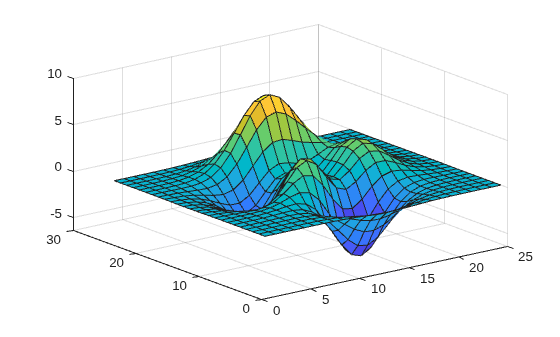

- Faites-en (comme toujours) une DataFrame
- (Optionnel) Faites un `sns.scatterplot` de ces données ('x' et 'y' pour les coordonnées, 'z' pour la hue)
- (Optionnel) Ajouter un early stopping que vous utiliserez dans `model.fit`.
- Aucun preprocessing nécessaire -> Faites un partionnement des données en données d'entraînement et de test, puis créez, compilez, entraînez le modèle.
- Comme au dessus, assignez le `model_fit` à une variable pour pouvoir plotter son historique et utilisez en plus le paramètre `validation_data=(X_valid, y_valid)` afin de voir les résultats sur les données de test en parallèle.

In [ ]:
def make_model_2( #TODO

df = #TODO
# Le scatterplot juste après:
# sns.scatterplot(

In [ ]:
X = #TODO
y = #TODO

X_train, X_valid, y_train, y_valid = #TODO

# Early stopping facultatif
# es =

m = make_model_2()
m.compile( #TODO
h = m.fit( #TODO

plt.plot( #TODO
plt.show()